# 10 — SARIMA, SARIMAX, Prophet y LSTM para el Parque Tunari

## Qué hace este notebook

Continúa el notebook 09. Parte de la **misma serie** (`indice_para_alertas` de `serie_mensual`, área `parque-tunari`) y de la **misma
validación** (entrenar hasta octubre del año anterior, pronosticar el año siguiente, 2019–2026), para que los resultados se puedan
comparar directamente con los del 09.

| Parte | Qué se hace |
|---|---|
| 1 | **Pruebas de Dickey–Fuller aumentada (ADF)**, con KPSS como contraste, para decidir cuántas diferencias necesita la serie |
| 2 | **SARIMA**: orden elegido con AICc (con `d` y `D` decididos por las pruebas), diagnóstico de residuos |
| 3 | **Una variable exógena nueva: el clima (ERA5)**. Se analizan varias candidatas (estacionariedad, correlación con rezago, causalidad de Granger) y se elige una **solo con datos anteriores a la primera prueba** |
| 4 | **SARIMAX** con esa variable, en tres escenarios de clima; además una versión con el **balance hídrico del mismo mes** (la asociación más fuerte), que sirve como límite superior |
| 5 | **Prophet** (sin y con la variable exógena) |
| 6 | **LSTM** (red neuronal recurrente, PyTorch), sin y con la variable exógena |
| 7 | Comparación con los modelos del 09 y con una prueba de significancia (Diebold–Mariano) |
| 8 | Pronóstico hasta diciembre de 2027 |

## Qué hay que tener presente antes de leerlo

- **La serie es corta** para modelos flexibles: 303 meses y solo 13 temporadas con VIIRS. Un LSTM y Prophet pueden **sobreajustar**; por eso se miden igual que los demás, y el
  resultado puede ser que **no mejoren**. Eso también es un resultado.
- **La variable exógena exige conocer el futuro del clima**, que no se conoce. Por eso SARIMAX y Prophet con clima se evalúan con **escenarios**: el realista usa la
  climatología (lo normal de cada mes) y el «oráculo» usa el clima que de verdad ocurrió (un **límite superior**: lo que se lograría con un pronóstico climático perfecto).
- **El clima viene de ERA5 en un solo punto** (lat −17,26, lon −66,35, ~4.200 m): es un indicador regional, no una medición del parque entero.
- **El factor de armonización (2,8715) se calculó con 2013–2025**, así que el índice contra el que se evalúa lleva una fuga leve de información. Afecta a todos los modelos por igual.

In [1]:
import json
import logging
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pmdarima as pm
import statsmodels.api as sm
import torch
import torch.nn as nn
from pmdarima.arima import ndiffs, nsdiffs
from prophet import Prophet
from scipy import stats
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, grangercausalitytests, kpss
from statsmodels.tsa.statespace.sarimax import SARIMAX

warnings.filterwarnings("ignore")
for nombre in ("cmdstanpy", "prophet", "pystan"):
    lg = logging.getLogger(nombre)
    lg.handlers = []
    lg.addHandler(logging.NullHandler())
    lg.propagate = False
    lg.setLevel(logging.CRITICAL)
torch.set_num_threads(2)
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)

ROOT = Path.cwd()
PAQUETE = ROOT / "entrega_backend" / "datos"
EXT = ROOT / "DATOS_PROCESADOS" / "externos"
SALIDA = ROOT / "DATOS_PROCESADOS" / "pronostico"
SALIDA.mkdir(parents=True, exist_ok=True)
AREA = "parque-tunari"
FACTOR = float(pd.read_csv(PAQUETE / "parametros.csv").set_index("clave").loc["factor_viirs_por_modis", "valor"])

serie = pd.read_csv(PAQUETE / "serie_mensual.csv", parse_dates=["mes"])
t = serie[serie.area_id == AREA].sort_values("mes").set_index("mes").asfreq("MS")
y = t["indice_para_alertas"].astype(float)
ylog = np.log1p(y)
print(f"Serie: {len(y)} meses ({y.index.min():%Y-%m} a {y.index.max():%Y-%m}); faltantes: {int(y.isna().sum())}; calidad: {t.calidad_indice.unique().tolist()}")

# ---- Clima ERA5 (un solo archivo coherente 2000-2026) -> variables mensuales
cj = json.loads((EXT / "era5_openmeteo_diario_tunari_2000_2026.json").read_text(encoding="utf-8"))
cd = pd.DataFrame(cj["daily"])
cd["time"] = pd.to_datetime(cd["time"])
cd = cd.set_index("time").rename(columns={"precipitation_sum": "lluvia", "temperature_2m_max": "tmax", "et0_fao_evapotranspiration": "et0"})
g = cd.resample("MS")
clima = pd.DataFrame({"lluvia_mes": g.lluvia.sum(), "tmax_media": g.tmax.mean(), "et0_mes": g.et0.sum(),
                      "dias_secos": g.lluvia.apply(lambda s: float((s < 1).sum())), "dias": g.lluvia.count()})
clima = clima[clima.dias.values >= clima.index.days_in_month.values].drop(columns="dias")  # solo meses completos
clima["balance_mes"] = clima.lluvia_mes - clima.et0_mes
clima["lluvia_3m"] = clima.lluvia_mes.rolling(3).sum()
clima["lluvia_6m"] = clima.lluvia_mes.rolling(6).sum()
clima["balance_3m"] = clima.balance_mes.rolling(3).sum()
CANDIDATAS = ["lluvia_mes", "lluvia_3m", "lluvia_6m", "balance_mes", "balance_3m", "tmax_media", "dias_secos"]
print(f"Clima mensual: {len(clima)} meses completos ({clima.index.min():%Y-%m} a {clima.index.max():%Y-%m})")
clima[CANDIDATAS].tail(3).round(1)

Serie: 303 meses (2001-08 a 2026-10); faltantes: 0; calidad: ['calibrado_localmente_en_tunari']
Clima mensual: 322 meses completos (2000-01 a 2026-10)


,lluvia_mes,lluvia_3m,lluvia_6m,balance_mes,balance_3m,tmax_media,dias_secos
time,,,,,,,
2026-08-01,43.4,48.5,352.2,-58.9,-243.6,10.1,26.0
2026-09-01,63.4,109.8,212.0,-55.9,-211.3,11.9,20.0
2026-10-01,58.9,165.7,203.8,-78.3,-193.2,12.4,22.0


## 1. Pruebas de Dickey–Fuller

### Qué mide la prueba (en palabras sencillas)
Una serie es **estacionaria** si su comportamiento no cambia con el tiempo (misma media y misma variabilidad, sin tendencia que se «escape»).
La mayoría de los modelos ARIMA lo necesitan. La **prueba de Dickey–Fuller aumentada (ADF)** parte de la hipótesis «la serie tiene una raíz unitaria»
(es decir, **no** es estacionaria y se desplaza como un camino aleatorio):

- **p < 0,05 → se rechaza la raíz unitaria:** la serie es estacionaria.
- **p ≥ 0,05 → no se puede rechazar:** hay que **diferenciar** (restar el valor anterior) antes de modelar.

Como la ADF a veces no rechaza por falta de potencia, se usa también **KPSS**, que parte de la hipótesis **contraria** (la serie *es* estacionaria):
si las dos coinciden, la conclusión es sólida; si discrepan, hay que tener cuidado.

La estacionalidad (el ciclo anual) es un tema aparte: la ADF no la detecta bien. Para decidir si hace falta una **diferencia estacional** (`D`) se usan pruebas
específicas (OCSB y Canova–Hansen).

In [2]:
def prueba_adf(x, nombre, regresion="c"):
    x = pd.Series(x).dropna()
    est, p, lags, nobs, crit, _ = adfuller(x, autolag="AIC", regression=regresion)
    try:
        k = kpss(x, regression="c" if regresion == "c" else "ct", nlags="auto")
        kp, kv = k[1], k[0]
    except Exception:
        kp, kv = np.nan, np.nan
    return {"serie": nombre, "n": nobs, "ADF_estadistico": round(est, 3), "ADF_p": round(p, 4), "ADF_rezagos": lags,
            "crit_1%": round(crit["1%"], 3), "crit_5%": round(crit["5%"], 3), "crit_10%": round(crit["10%"], 3),
            "KPSS_estadistico": round(kv, 3) if kv == kv else np.nan, "KPSS_p": round(kp, 4) if kp == kp else np.nan,
            "ADF (5 %)": "estacionaria" if p < 0.05 else "raíz unitaria",
            "KPSS (5 %)": "estacionaria" if (kp == kp and kp > 0.05) else "NO estacionaria",
            }

v = y.loc["2013-01-01":]
series_prueba = [
    ("índice (todo, 2001-2026)", y),
    ("log(1 + índice) (todo)", ylog),
    ("índice (solo era VIIRS, 2013+)", v),
    ("log(1 + índice) (era VIIRS)", np.log1p(v)),
    ("log(1 + índice), 1 diferencia (d=1)", ylog.diff()),
    ("log(1 + índice), diferencia estacional (D=1)", ylog.diff(12)),
    ("log(1 + índice), d=1 y D=1", ylog.diff().diff(12)),
]
adf_tabla = pd.DataFrame([prueba_adf(s, n) for n, s in series_prueba])
adf_tabla.drop(columns=["crit_1%", "crit_10%"])

,serie,n,ADF_estadistico,ADF_p,ADF_rezagos,crit_5%,KPSS_estadistico,KPSS_p,ADF (5 %),KPSS (5 %)
0,"índice (todo, 2001-2026)",290,-3.750,0.0035,12,-2.872,0.742,0.01,estacionaria,NO estacionaria
1,log(1 + índice) (todo),291,-2.908,0.0444,11,-2.872,1.105,0.01,estacionaria,NO estacionaria
2,"índice (solo era VIIRS, 2013+)",153,-3.111,0.0257,12,-2.881,0.112,0.10,estacionaria,estacionaria
3,log(1 + índice) (era VIIRS),161,-9.150,0.0000,4,-2.880,0.138,0.10,estacionaria,estacionaria
4,"log(1 + índice), 1 diferencia (d=1)",291,-13.600,0.0000,10,-2.872,0.012,0.10,estacionaria,estacionaria
5,"log(1 + índice), diferencia estacional (D=1)",278,-6.941,0.0000,12,-2.872,0.020,0.10,estacionaria,estacionaria
6,"log(1 + índice), d=1 y D=1",275,-8.326,0.0000,14,-2.872,0.086,0.10,estacionaria,estacionaria


In [3]:
# Lectura automática de la tabla (se regenera con los datos)
for _, r in adf_tabla.iterrows():
    if r["ADF (5 %)"] == "estacionaria" and r["KPSS (5 %)"] == "estacionaria":
        print(f"[coinciden: estacionaria]    {r['serie']}")
    elif r["ADF (5 %)"] != r["KPSS (5 %)"]:
        print(f"[DISCREPAN] ADF dice '{r['ADF (5 %)']}' y KPSS dice '{r['KPSS (5 %)']}'   {r['serie']}")
    else:
        print(f"[coinciden: {r['ADF (5 %)']}]    {r['serie']}")
print("\nNota: cuando ADF y KPSS discrepan en la serie completa pero coinciden en la era VIIRS (2013+), una explicación habitual es un CAMBIO DE NIVEL")
print("(aquí, el paso de MODIS a VIIRS en 2012): KPSS es sensible a él y la ADF menos. Es consistente con el control de época que ya necesitó el modelo del notebook 09.")

[DISCREPAN] ADF dice 'estacionaria' y KPSS dice 'NO estacionaria'   índice (todo, 2001-2026)
[DISCREPAN] ADF dice 'estacionaria' y KPSS dice 'NO estacionaria'   log(1 + índice) (todo)
[coinciden: estacionaria]    índice (solo era VIIRS, 2013+)
[coinciden: estacionaria]    log(1 + índice) (era VIIRS)
[coinciden: estacionaria]    log(1 + índice), 1 diferencia (d=1)
[coinciden: estacionaria]    log(1 + índice), diferencia estacional (D=1)
[coinciden: estacionaria]    log(1 + índice), d=1 y D=1

Nota: cuando ADF y KPSS discrepan en la serie completa pero coinciden en la era VIIRS (2013+), una explicación habitual es un CAMBIO DE NIVEL
(aquí, el paso de MODIS a VIIRS en 2012): KPSS es sensible a él y la ADF menos. Es consistente con el control de época que ya necesitó el modelo del notebook 09.


In [4]:
# Con tendencia determinista (regresión 'ct'): ¿cambia la conclusión?
pd.DataFrame([prueba_adf(ylog, "log(1 + índice), con tendencia (ct)", "ct")]).drop(columns=["crit_1%", "crit_10%"])

,serie,n,ADF_estadistico,ADF_p,ADF_rezagos,crit_5%,KPSS_estadistico,KPSS_p,ADF (5 %),KPSS (5 %)
0,"log(1 + índice), con tendencia (ct)",286,-5.443,0.0,16,-3.426,0.018,0.1,estacionaria,estacionaria


Diferencias recomendadas (datos hasta oct-2018): {'d (ADF)': 0, 'd (KPSS)': 0, 'D (OCSB)': 0, 'D (Canova-Hansen)': 0}
-> se parte de d = 0 y D = 0; cada prueba de validación vuelve a decidirlos con SUS datos.


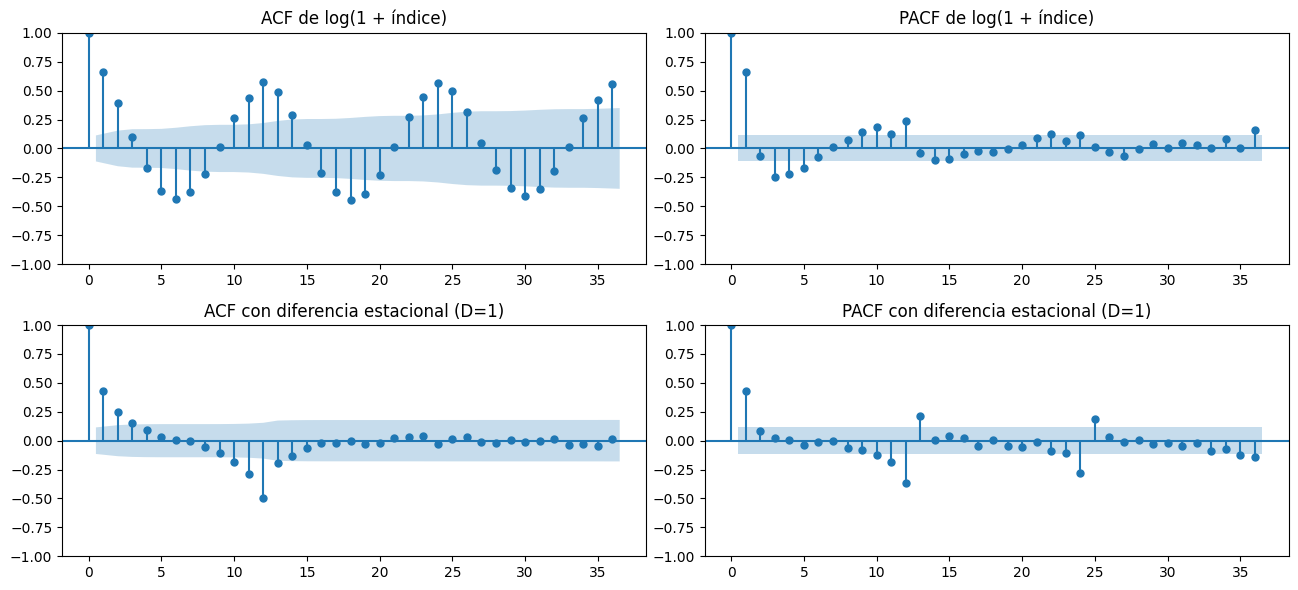

In [5]:
# Cuántas diferencias recomiendan las pruebas, usando SOLO datos hasta octubre de 2018 (antes de la primera prueba de validación)
base = ylog.loc[:"2018-10-01"]
rec = {
    "d (ADF)": int(ndiffs(base, test="adf", max_d=2)),
    "d (KPSS)": int(ndiffs(base, test="kpss", max_d=2)),
    "D (OCSB)": int(nsdiffs(base, m=12, test="ocsb", max_D=1)),
    "D (Canova-Hansen)": int(nsdiffs(base, m=12, test="ch", max_D=1)),
}
print("Diferencias recomendadas (datos hasta oct-2018):", rec)
D_PRUEBAS = int(max(rec["D (OCSB)"], rec["D (Canova-Hansen)"]))
D_REGULAR = int(min(rec["d (ADF)"], rec["d (KPSS)"]))
print(f"-> se parte de d = {D_REGULAR} y D = {D_PRUEBAS}; cada prueba de validación vuelve a decidirlos con SUS datos.")

fig, ax = plt.subplots(2, 2, figsize=(13, 6))
plot_acf(ylog.dropna(), lags=36, ax=ax[0, 0], title="ACF de log(1 + índice)")
plot_pacf(ylog.dropna(), lags=36, ax=ax[0, 1], title="PACF de log(1 + índice)", method="ywm")
plot_acf(ylog.diff(12).dropna(), lags=36, ax=ax[1, 0], title="ACF con diferencia estacional (D=1)")
plot_pacf(ylog.diff(12).dropna(), lags=36, ax=ax[1, 1], title="PACF con diferencia estacional (D=1)", method="ywm")
plt.tight_layout(); plt.show()

### Cómo leer la tabla de Dickey–Fuller

- Si en **ADF y KPSS** la serie sale «estacionaria», **no hace falta diferenciar** (`d = 0`).
- Aunque salga estacionaria, la serie tiene un **ciclo anual muy marcado** (se ve en la ACF: picos cada 12 meses). Eso lo capta el componente **estacional** del SARIMA,
  no la diferenciación regular.
- Una diferencia de más (**sobrediferenciar**) mete ruido: por eso se prefiere la menor diferenciación que deje la serie estacionaria.

## 2. SARIMA

`SARIMA(p,d,q)(P,D,Q)₁₂`: modela cómo un mes depende de los anteriores (parte regular) y del mismo mes de los años anteriores (parte estacional).

- Se trabaja sobre `log(1 + índice)`, con la corrección del sesgo del logaritmo al volver a la escala original (se pronostica la media, no la mediana).
- **Cada prueba de validación elige su propio orden** con el criterio **AICc** (búsqueda por pasos de `pmdarima`), usando solo sus datos de entrenamiento. Así no se «ve el futuro»
  al elegir el modelo.
- El orden se ajusta con `statsmodels` para poder diagnosticar residuos y compararlo con SARIMAX en igualdad de condiciones.

In [6]:
H = 14  # meses a pronosticar: de noviembre del año anterior a diciembre del año objetivo


def futuro(origen, n=H):
    return pd.date_range(origen + pd.offsets.MonthBegin(1), periods=n, freq="MS")


def volver(media_log, var_log, lo_log, hi_log):
    # Corrección del sesgo del logaritmo: media de una lognormal = exp(mu + var/2)
    return np.expm1(np.asarray(media_log) + var_log / 2), np.maximum(np.expm1(np.asarray(lo_log)), 0), np.expm1(np.asarray(hi_log))


def seleccionar_orden(ylog_tr):
    d_ = int(min(ndiffs(ylog_tr, test="adf", max_d=1), 1))
    D_ = int(min(nsdiffs(ylog_tr, m=12, test="ocsb", max_D=1), 1))
    m = pm.auto_arima(ylog_tr.values, start_p=0, start_q=0, max_p=3, max_q=3, start_P=0, start_Q=0, max_P=2, max_Q=2, m=12,
                      d=d_, D=D_, seasonal=True, stepwise=True, information_criterion="aicc", error_action="ignore",
                      suppress_warnings=True, trace=False)
    return {"orden": m.order, "estacional": m.seasonal_order, "d": d_, "D": D_, "aicc": float(m.aicc())}


def ajustar_sm(ylog_tr, sel, exog=None):
    tendencia = "c" if (sel["orden"][1] == 0 and sel["estacional"][1] == 0) else None
    mod = SARIMAX(ylog_tr, exog=exog, order=sel["orden"], seasonal_order=sel["estacional"], trend=tendencia,
                  enforce_stationarity=False, enforce_invertibility=False)
    return mod.fit(disp=False, maxiter=300)


def pronosticar_sm(res, ylog_tr, fut, exog_fut=None):
    fc = res.get_forecast(steps=len(fut), exog=exog_fut)
    ci = fc.conf_int(alpha=0.10)
    var = float(np.nanvar(res.resid.iloc[24:]))
    e, lo, hi = volver(fc.predicted_mean.values, var, ci.iloc[:, 0].values, ci.iloc[:, 1].values)
    return pd.DataFrame({"esperado": e, "p05": lo, "p95": hi}, index=fut)


# Ajuste completo con TODA la serie (hasta oct-2026), para el diagnóstico de residuos
sel_final = seleccionar_orden(ylog.dropna())
res_sarima = ajustar_sm(ylog.dropna(), sel_final)
print(f"Orden elegido (toda la serie): SARIMA{sel_final['orden']}x{sel_final['estacional']}   d={sel_final['d']}  D={sel_final['D']}   AICc={sel_final['aicc']:.1f}")
print(res_sarima.summary().tables[1])
ar_s = float(res_sarima.params.get("ar.S.L12", np.nan))
if ar_s == ar_s and ar_s >= 0.98:
    print(f"\nOJO: el coeficiente AR estacional vale {ar_s:.3f} (≈ 1): el componente estacional es casi no estacionario, compensado por el MA estacional. "
          "Las pruebas de diferencia estacional (OCSB y Canova-Hansen) recomendaron D = 0, pero conviene tenerlo presente: el ciclo anual es muy persistente.")

Orden elegido (toda la serie): SARIMA(1, 0, 1)x(1, 0, 1, 12)   d=0  D=0   AICc=548.1
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept      0.0134      0.008      1.753      0.080      -0.002       0.028
ar.L1          0.5357      0.102      5.227      0.000       0.335       0.737
ma.L1         -0.1805      0.116     -1.550      0.121      -0.409       0.048
ar.S.L12       1.0076      0.010    103.930      0.000       0.989       1.027
ma.S.L12      -0.9486      0.089    -10.709      0.000      -1.122      -0.775
sigma2         0.3064      0.030     10.264      0.000       0.248       0.365

OJO: el coeficiente AR estacional vale 1.008 (≈ 1): el componente estacional es casi no estacionario, compensado por el MA estacional. Las pruebas de diferencia estacional (OCSB y Canova-Hansen) recomendaron D = 0, pero conviene tenerlo presente: el ciclo anual es muy persistente.


Ljung-Box (autocorrelación de los residuos):
    lb_stat  lb_pvalue
6    1.8156     0.9359
12   7.5255     0.8210
24  13.8706     0.9495
Jarque-Bera (normalidad): estadístico 18.9, p = 7.894e-05  ->  residuos NO normales (esperable: hay muchos ceros y picos)


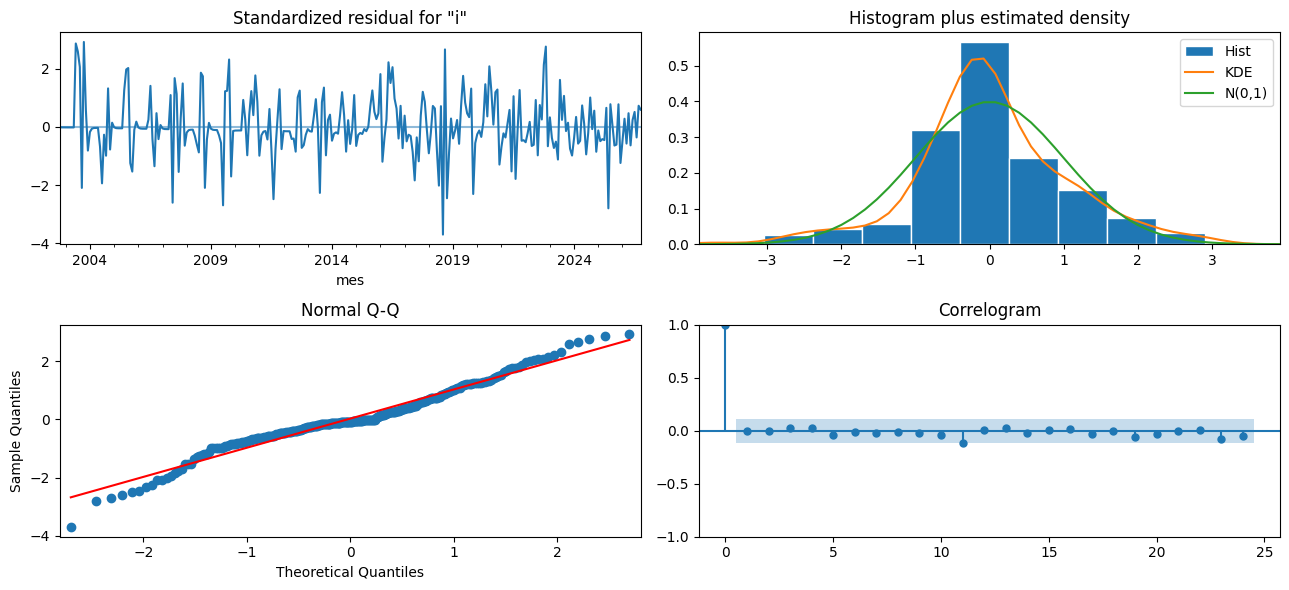

In [7]:
# Diagnóstico de residuos: ¿quedó estructura sin explicar? (Ljung-Box: p > 0,05 = residuos sin autocorrelación)
from statsmodels.stats.diagnostic import acorr_ljungbox

resid = res_sarima.resid.iloc[24:]
lb = acorr_ljungbox(resid, lags=[6, 12, 24], return_df=True)
jb = stats.jarque_bera(resid)
print("Ljung-Box (autocorrelación de los residuos):")
print(lb.round(4).to_string())
print(f"Jarque-Bera (normalidad): estadístico {jb.statistic:.1f}, p = {jb.pvalue:.4g}  ->  {'residuos aprox. normales' if jb.pvalue > 0.05 else 'residuos NO normales (esperable: hay muchos ceros y picos)'}")
res_sarima.plot_diagnostics(figsize=(13, 6), lags=24); plt.tight_layout(); plt.show()

## 3. La variable exógena: el clima

Una variable **exógena** es información externa que ayuda a explicar la serie. Aquí probamos el **clima** (ERA5, un punto del Tunari), porque el fuego depende de qué tan seco está el ambiente.

### Qué se analiza de cada candidata
1. **Estacionariedad** (ADF/KPSS), como antes.
2. **Correlación con rezago** entre el clima de hace *L* meses y el índice de ahora. Se hace sobre **anomalías** (cada valor menos lo normal de su mes, dividido por su variabilidad)
   para que no se «correlacionen» solo porque ambas variables tienen estación.
3. **Causalidad de Granger**: ¿conocer el clima pasado mejora la predicción del índice? (Es *predictiva*, no una prueba de causa y efecto.)
4. **Regla de elección:** se escoge la candidata y el rezago (L ≥ 1, para que sea conocida al pronosticar) con mayor |correlación| **y** Granger significativo.

> **Para no hacer trampa**, el análisis y la elección usan **solo datos hasta octubre de 2018**, antes de la primera prueba de validación.

In [8]:
CORTE_SEL = pd.Timestamp("2018-10-01")


def anomalia(s, hasta):
    base = s.loc[:hasta].dropna()
    mu = base.groupby(base.index.month).mean()
    sd = base.groupby(base.index.month).std().replace(0, np.nan)
    return (s - s.index.month.map(mu).values) / s.index.month.map(sd).values


ya = anomalia(ylog, CORTE_SEL)
filas, grang = [], []
for c in CANDIDATAS:
    xa = anomalia(clima[c], CORTE_SEL)
    for L in range(0, 7):
        par = pd.concat([ya, xa.shift(L)], axis=1, keys=["y", "x"]).loc[:CORTE_SEL].dropna()
        rho = stats.spearmanr(par.y, par.x)[0]
        filas.append({"variable": c, "rezago_meses": L, "spearman": rho, "n": len(par)})
    par = pd.concat([ya, xa], axis=1, keys=["y", "x"]).loc[:CORTE_SEL].dropna()
    gr = grangercausalitytests(par[["y", "x"]], maxlag=6, verbose=False)
    for L in range(1, 7):
        grang.append({"variable": c, "rezago_meses": L, "granger_p": gr[L][0]["ssr_ftest"][1]})
corr = pd.DataFrame(filas)
gr_t = pd.DataFrame(grang)
exo = corr.merge(gr_t, on=["variable", "rezago_meses"], how="left")

print("Correlación (Spearman) entre la anomalía del índice y la del clima de hace L meses; datos hasta oct-2018")
print(corr.pivot(index="variable", columns="rezago_meses", values="spearman").round(2).to_string())
print("\nCausalidad de Granger (p-valor; < 0,05 = el clima ayuda a predecir el índice):")
print(gr_t.pivot(index="variable", columns="rezago_meses", values="granger_p").round(3).to_string())

Correlación (Spearman) entre la anomalía del índice y la del clima de hace L meses; datos hasta oct-2018
rezago_meses     0     1     2     3     4     5     6
variable                                              
balance_3m   -0.22 -0.06 -0.03  0.03  0.06  0.08  0.06
balance_mes  -0.26 -0.08 -0.06  0.00 -0.05  0.05  0.05
dias_secos    0.36  0.18  0.19  0.17  0.08  0.12  0.12
lluvia_3m    -0.16 -0.00  0.03  0.07  0.09  0.13  0.11
lluvia_6m    -0.02  0.09  0.11  0.15  0.16  0.12  0.09
lluvia_mes   -0.22 -0.05 -0.03  0.01 -0.02  0.07  0.07
tmax_media    0.26  0.21  0.15  0.15  0.14  0.08  0.10

Causalidad de Granger (p-valor; < 0,05 = el clima ayuda a predecir el índice):
rezago_meses      1      2      3      4      5      6
variable                                              
balance_3m    0.786  0.980  0.637  0.601  0.683  0.767
balance_mes   0.618  0.861  0.756  0.794  0.484  0.611
dias_secos    0.554  0.149  0.245  0.277  0.327  0.497
lluvia_3m     0.904  0.965  0.619  0.633  0.6

In [9]:
# Estacionariedad de las candidatas (todo el período disponible) y elección
adf_exo = pd.DataFrame([prueba_adf(clima[c], c) for c in CANDIDATAS]).drop(columns=["crit_1%", "crit_10%", "KPSS_estadistico", "ADF_rezagos"])
print(adf_exo.to_string(index=False))

cand = exo[(exo.rezago_meses >= 1)].copy()
cand["abs_rho"] = cand.spearman.abs()
con_granger = cand[cand.granger_p < 0.05]
elegida = (con_granger if len(con_granger) else cand).sort_values("abs_rho", ascending=False).iloc[0]
EXOG_VAR, EXOG_LAG = str(elegida.variable), int(elegida.rezago_meses)
print(f"\nELEGIDA: {EXOG_VAR} con rezago de {EXOG_LAG} mes(es):  Spearman = {elegida.spearman:.2f},  Granger p = {elegida.granger_p:.3f}"
      + ("" if len(con_granger) else "   (ATENCIÓN: ninguna candidata superó Granger; se tomó la de mayor correlación)"))
SECO_ES_ALTO = {"dias_secos", "tmax_media"}  # para estas, «año seco» = valor alto
top = cand.sort_values("abs_rho", ascending=False).head(8)[["variable", "rezago_meses", "spearman", "granger_p"]].round(3)
l0 = exo[exo.rezago_meses == 0].assign(a=lambda d: d.spearman.abs()).sort_values("a", ascending=False).iloc[0]
print(f"\nMayor asociación del MISMO mes (rezago 0): {l0.variable}, Spearman = {l0.spearman:.2f}")
print(f"Mayor asociación con rezago >= 1 mes:       {EXOG_VAR} (rezago {EXOG_LAG}), Spearman = {elegida.spearman:.2f}   | Granger mínimo entre todas las candidatas: p = {cand.granger_p.min():.3f}")
print("Lectura: el clima del mismo mes se asocia con el índice (mes seco, más fuego), pero con 1 mes o más de anticipación casi no hay señal: sirve para EXPLICAR un mes, no para predecirlo")
print("sin un pronóstico del clima. Por eso se prueba también una versión con el balance hídrico del MISMO mes (rezago 0), con escenarios y en versión 'oráculo'.")
top

      serie   n  ADF_estadistico  ADF_p  crit_5%  KPSS_p     ADF (5 %)      KPSS (5 %)
 lluvia_mes 306           -3.160 0.0225   -2.871  0.1000  estacionaria    estacionaria
  lluvia_3m 306           -3.145 0.0234   -2.871  0.1000  estacionaria    estacionaria
  lluvia_6m 303           -3.280 0.0158   -2.871  0.0889  estacionaria    estacionaria
balance_mes 306           -3.062 0.0295   -2.871  0.1000  estacionaria    estacionaria
 balance_3m 306           -3.043 0.0311   -2.871  0.1000  estacionaria    estacionaria
 tmax_media 304           -2.865 0.0496   -2.871  0.0100  estacionaria NO estacionaria
 dias_secos 304           -1.739 0.4109   -2.871  0.0100 raíz unitaria NO estacionaria

ELEGIDA: tmax_media con rezago de 1 mes(es):  Spearman = 0.21,  Granger p = 0.308   (ATENCIÓN: ninguna candidata superó Granger; se tomó la de mayor correlación)

Mayor asociación del MISMO mes (rezago 0): dias_secos, Spearman = 0.36
Mayor asociación con rezago >= 1 mes:       tmax_media (rezago 1), Sp

,variable,rezago_meses,spearman,granger_p
36,tmax_media,1,0.208,0.308
44,dias_secos,2,0.190,0.149
43,dias_secos,1,0.176,0.554
45,dias_secos,3,0.168,0.245
18,lluvia_6m,4,0.164,0.601
38,tmax_media,3,0.150,0.653
17,lluvia_6m,3,0.149,0.512
37,tmax_media,2,0.146,0.575


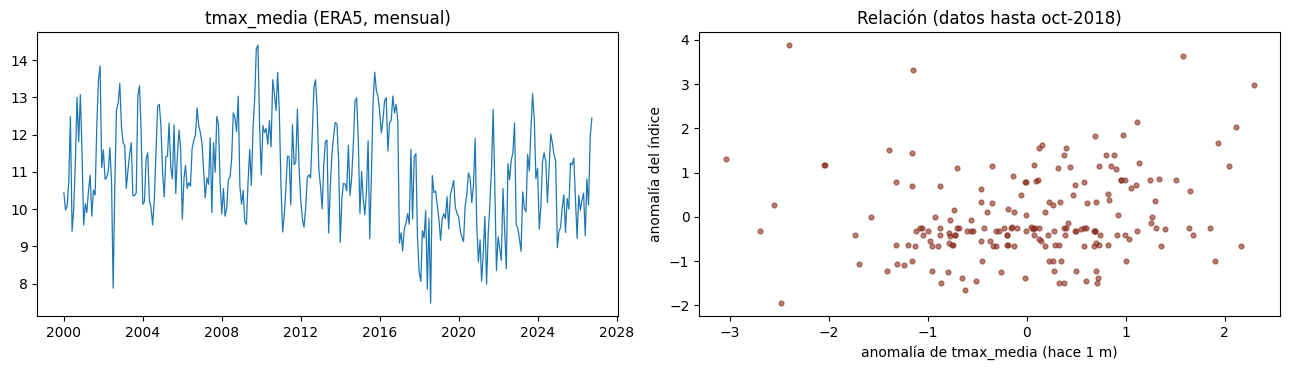

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].plot(clima.index, clima[EXOG_VAR], lw=0.9, color="#1f77b4"); ax[0].set_title(f"{EXOG_VAR} (ERA5, mensual)")
par = pd.concat([ya, anomalia(clima[EXOG_VAR], CORTE_SEL).shift(EXOG_LAG)], axis=1, keys=["y", "x"]).loc[:CORTE_SEL].dropna()
ax[1].scatter(par.x, par.y, s=12, alpha=0.6, color="#8a2d1d"); ax[1].set_xlabel(f"anomalía de {EXOG_VAR} (hace {EXOG_LAG} m)"); ax[1].set_ylabel("anomalía del índice")
ax[1].set_title("Relación (datos hasta oct-2018)")
plt.tight_layout(); plt.show()

### Cómo se usa la variable en el pronóstico
Al pronosticar un mes futuro *t* se usa el clima de *t − L*. Cuando ese mes ya ocurrió, se usa el valor real. Cuando todavía no ocurrió, hay que **suponer** un clima. Se prueban:

| Escenario | Qué supone | Para qué sirve |
|---|---|---|
| **climatología** | lo normal de cada mes (mediana histórica) | El caso **realista**: no sabemos el clima futuro |
| **seco** / **húmedo** | percentil 20 / 80 de cada mes (invertido para variables donde «alto» = seco) | Mostrar cuánto cambiaría el pronóstico |
| **oráculo** | el clima que realmente ocurrió | **Solo en la validación**: un límite superior de lo que aportaría un pronóstico climático perfecto |

In [11]:
def exog_extendida(origen, fut, escenario, var=None, lag=None):
    # Serie mensual del clima extendida con el escenario para los meses posteriores al origen, estandarizada y rezagada
    var = EXOG_VAR if var is None else var
    lag = EXOG_LAG if lag is None else lag
    X = clima[var].copy()
    idx = pd.date_range(X.index.min(), max(fut[-1], X.index.max()), freq="MS")
    Xe = X.reindex(idx)
    hist = X.loc[:origen]
    cal = hist.groupby(hist.index.month)
    alto_seco = var in SECO_ES_ALTO
    if escenario == "seco":
        ref = cal.quantile(0.8 if alto_seco else 0.2)
    elif escenario == "humedo":
        ref = cal.quantile(0.2 if alto_seco else 0.8)
    else:
        ref = cal.median()
    for m in idx[idx > origen]:
        if escenario == "oraculo" and not np.isnan(Xe.get(m, np.nan)):
            continue
        Xe.loc[m] = ref.loc[m.month]
    Z = (Xe - hist.mean()) / hist.std()
    return Z.shift(lag)


def modelos_sarimax(ylog_tr, sel, origen, fut, escenarios, var=None, lag=None):
    out = {}
    Zc = exog_extendida(origen, fut, "climatologia", var, lag)
    res = ajustar_sm(ylog_tr, sel, exog=Zc.loc[ylog_tr.index].values.reshape(-1, 1))
    coef = float(res.params.get("x1", np.nan))
    for esc in escenarios:
        Z = exog_extendida(origen, fut, esc, var, lag)
        out[esc] = pronosticar_sm(res, ylog_tr, fut, exog_fut=Z.loc[fut].values.reshape(-1, 1))
    return out, res, coef


# SARIMAX con toda la serie: coeficiente de la variable exógena y comparación con SARIMA
origen_final = y.dropna().index.max()
fut_final = futuro(origen_final)
yl = ylog.dropna()
sx, res_sx, coef_sx = modelos_sarimax(yl, sel_final, origen_final, fut_final, ["climatologia"])
print(res_sx.summary().tables[1])
lr = 2 * (res_sx.llf - res_sarima.llf)
print(f"\nComparación con SARIMA (mismo orden): AIC SARIMA = {res_sarima.aic:.1f}  |  AIC SARIMAX = {res_sx.aic:.1f}  (menor es mejor)")
print(f"Prueba de razón de verosimilitud (1 parámetro más): chi2 = {lr:.2f}, p = {stats.chi2.sf(max(lr, 0), 1):.4f}")

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept      0.0150      0.008      1.877      0.061      -0.001       0.031
x1             0.0435      0.048      0.907      0.365      -0.051       0.137
ar.L1          0.5286      0.113      4.686      0.000       0.308       0.750
ma.L1         -0.1939      0.134     -1.449      0.147      -0.456       0.068
ar.S.L12       1.0063      0.010    103.455      0.000       0.987       1.025
ma.S.L12      -0.9426      0.081    -11.581      0.000      -1.102      -0.783
sigma2         0.3068      0.029     10.762      0.000       0.251       0.363

Comparación con SARIMA (mismo orden): AIC SARIMA = 517.0  |  AIC SARIMAX = 518.5  (menor es mejor)
Prueba de razón de verosimilitud (1 parámetro más): chi2 = 0.59, p = 0.4442


## 4. Prophet

Prophet descompone la serie en **tendencia + estacionalidad anual** (+ efectos opcionales). Lo usamos sobre `log(1 + índice)`, con estacionalidad anual (series de Fourier de orden 8), sin
estacionalidad semanal ni diaria (los datos son mensuales) y banda del 90 %. La variante con regresor agrega la variable climática (estandarizada y rezagada).

In [12]:
def pron_prophet(ylog_tr, fut, Z=None):
    df = pd.DataFrame({"ds": ylog_tr.index, "y": ylog_tr.values})
    m = Prophet(yearly_seasonality=8, weekly_seasonality=False, daily_seasonality=False, interval_width=0.90, uncertainty_samples=300)
    if Z is not None:
        df["x"] = Z.loc[ylog_tr.index].values
        m.add_regressor("x")
    m.fit(df)
    fdf = pd.DataFrame({"ds": fut})
    if Z is not None:
        fdf["x"] = Z.loc[fut].values
    pr = m.predict(fdf)
    var = float(np.var(df.y.values - m.predict(df[["ds"] + (["x"] if Z is not None else [])])["yhat"].values))
    e, lo, hi = volver(pr["yhat"].values, var, pr["yhat_lower"].values, pr["yhat_upper"].values)
    return pd.DataFrame({"esperado": e, "p05": lo, "p95": hi}, index=fut)

## 5. LSTM

Una **LSTM** es una red neuronal que lee una secuencia (aquí, los **últimos 24 meses**) y aprende patrones que dependen del orden. Se entrena para predecir de una vez los siguientes
**14 meses** («directo multisalida»).

- **Entradas por mes:** `log(1 + índice)` estandarizado + el mes del año como seno y coseno. La variante con exógena agrega el clima rezagado.
- **Arquitectura mínima** (una capa LSTM de 16 unidades + una capa lineal), con **regularización** y **parada temprana** con una validación al final del entrenamiento, y **un conjunto de 5 redes** con semillas distintas.
- **Banda del 90 %:** desviación de los errores de validación por horizonte combinada con la dispersión entre redes (es una banda aproximada).
- **Limitación honesta:** con ~170 a 280 ventanas de entrenamiento, el modelo tiene **muy pocos datos**; es probable que no supere a los modelos clásicos.

In [13]:
class RedLSTM(nn.Module):
    def __init__(self, entradas, ocultas, salidas):
        super().__init__()
        self.lstm = nn.LSTM(entradas, ocultas, batch_first=True)
        self.drop = nn.Dropout(0.1)
        self.cabeza = nn.Linear(ocultas, salidas)

    def forward(self, x):
        o, _ = self.lstm(x)
        return self.cabeza(self.drop(o[:, -1, :]))


def pron_lstm(ylog_tr, fut, Z=None, ventana=24, semillas=5):
    yv = ylog_tr.values.astype(float)
    n = len(yv)
    mu, sd = yv.mean(), yv.std()
    z = (yv - mu) / sd
    mes = ylog_tr.index.month.values
    cols = [z, np.sin(2 * np.pi * mes / 12), np.cos(2 * np.pi * mes / 12)]
    if Z is not None:
        cols.append(Z.loc[ylog_tr.index].values.astype(float))
    F = np.stack(cols, 1).astype(np.float32)
    Hh = len(fut)
    ids = range(0, n - ventana - Hh + 1)
    Xw = np.stack([F[i:i + ventana] for i in ids])
    Yw = np.stack([z[i + ventana:i + ventana + Hh] for i in ids]).astype(np.float32)
    nval = max(int(0.15 * len(Xw)), 12)
    Xtr, Ytr, Xva, Yva = map(torch.tensor, (Xw[:-nval], Yw[:-nval], Xw[-nval:], Yw[-nval:]))
    ultima = torch.tensor(F[-ventana:][None])
    preds, vpreds = [], []
    for s in range(semillas):
        torch.manual_seed(100 + s)
        net = RedLSTM(F.shape[1], 16, Hh)
        opt = torch.optim.AdamW(net.parameters(), lr=5e-3, weight_decay=1e-3)
        mejor, estado, paciencia = np.inf, None, 0
        for ep in range(400):
            net.train()
            perm = torch.randperm(len(Xtr))
            for b in range(0, len(Xtr), 32):
                idx = perm[b:b + 32]
                opt.zero_grad()
                nn.functional.mse_loss(net(Xtr[idx]), Ytr[idx]).backward()
                opt.step()
            net.eval()
            with torch.no_grad():
                v = nn.functional.mse_loss(net(Xva), Yva).item()
            if v < mejor - 1e-5:
                mejor, estado, paciencia = v, {k: x.clone() for k, x in net.state_dict().items()}, 0
            else:
                paciencia += 1
                if paciencia >= 25:
                    break
        net.load_state_dict(estado)
        net.eval()
        with torch.no_grad():
            preds.append(net(ultima).numpy()[0])
            vpreds.append(net(Xva).numpy())
    pm_ = np.mean(preds, 0)
    sd_ens = np.std(preds, 0)
    res_va = Yva.numpy() - np.mean(vpreds, 0)
    sd_h = np.maximum(res_va.std(0), 0.05)
    sd_tot = np.sqrt(sd_h ** 2 + sd_ens ** 2) * sd
    media_log = mu + sd * pm_
    var_log = float(np.mean((sd_h * sd) ** 2))  # misma corrección del sesgo del logaritmo que los demás modelos
    e, lo, hi = volver(media_log, var_log, media_log - 1.645 * sd_tot, media_log + 1.645 * sd_tot)
    return pd.DataFrame({"esperado": e, "p05": lo, "p95": hi}, index=fut)

## 6. Validación rodante (2019–2026)

Igual que en el 09: para cada año objetivo se entrena **solo con datos hasta octubre del año anterior** y se pronostican los 14 meses siguientes; se evalúan los meses del año objetivo.
El orden del SARIMA se **vuelve a elegir en cada prueba** y la variable exógena es **la elegida con datos hasta 2018**.

> Tarda varios minutos (cada prueba ajusta SARIMA, SARIMAX, dos Prophet y dos LSTM con cinco semillas).

In [14]:
import time

ESCENARIOS_VAL = ["climatologia", "oraculo"]
filas, ordenes = [], []
t_ini = time.time()
for anio in range(2019, 2027):
    origen = pd.Timestamp(f"{anio - 1}-10-01")
    fut = futuro(origen)
    yl_tr = ylog.loc[:origen].dropna()
    yl_tr.index.freq = "MS"
    res_f = {}
    # SARIMA
    sel = seleccionar_orden(yl_tr)
    ordenes.append({"anio_objetivo": anio, "orden": str(sel["orden"]), "estacional": str(sel["estacional"]), "d": sel["d"], "D": sel["D"], "AICc": round(sel["aicc"], 1)})
    rs = ajustar_sm(yl_tr, sel)
    res_f["S1_sarima"] = pronosticar_sm(rs, yl_tr, fut)
    # SARIMAX en escenarios
    sx_f, _, _ = modelos_sarimax(yl_tr, sel, origen, fut, ESCENARIOS_VAL)
    res_f["S2_sarimax_clima_normal"] = sx_f["climatologia"]
    res_f["S2o_sarimax_oraculo"] = sx_f["oraculo"]
    sx3, _, _ = modelos_sarimax(yl_tr, sel, origen, fut, ESCENARIOS_VAL, var="balance_3m", lag=0)
    res_f["S3_sarimax_balance3m_clima_normal"] = sx3["climatologia"]
    res_f["S3o_sarimax_balance3m_oraculo"] = sx3["oraculo"]
    # Prophet
    res_f["P1_prophet"] = pron_prophet(yl_tr, fut)
    Zc = exog_extendida(origen, fut, "climatologia")
    res_f["P2_prophet_clima_normal"] = pron_prophet(yl_tr, fut, Z=Zc)
    res_f["P2o_prophet_oraculo"] = pron_prophet(yl_tr, fut, Z=exog_extendida(origen, fut, "oraculo"))
    # LSTM (la exógena entra solo con valores ya observados dentro de la ventana: no necesita escenario)
    res_f["L1_lstm"] = pron_lstm(yl_tr, fut)
    res_f["L2_lstm_clima"] = pron_lstm(yl_tr, fut, Z=Zc)
    for modelo, df in res_f.items():
        df = df[df.index.year == anio]
        df = df[df.index.isin(y.dropna().index)]
        df = df.assign(modelo=modelo, observado=y.loc[df.index].values, origen_hasta=origen,
                       horizonte_meses=(df.index.year - origen.year) * 12 + df.index.month - origen.month)
        filas.append(df.reset_index(names="mes"))
    print(f"  {anio} listo  ({time.time() - t_ini:.0f} s)  SARIMA{sel['orden']}x{sel['estacional']}")
bt = pd.concat(filas, ignore_index=True)
bt["anio"], bt["mes_num"] = bt.mes.dt.year, bt.mes.dt.month
print(f"\nPronósticos evaluados: {len(bt)} ({bt.modelo.nunique()} modelos × {len(bt) // bt.modelo.nunique()} meses)")
pd.DataFrame(ordenes)

  2019 listo  (21 s)  SARIMA(1, 0, 0)x(1, 0, 1, 12)


  2020 listo  (37 s)  SARIMA(1, 0, 0)x(1, 0, 1, 12)


  2021 listo  (57 s)  SARIMA(1, 0, 0)x(1, 0, 1, 12)


  2022 listo  (76 s)  SARIMA(1, 0, 0)x(1, 0, 1, 12)


  2023 listo  (97 s)  SARIMA(1, 0, 0)x(1, 0, 1, 12)


  2024 listo  (122 s)  SARIMA(1, 0, 0)x(2, 0, 0, 12)


  2025 listo  (148 s)  SARIMA(1, 0, 0)x(1, 0, 1, 12)


  2026 listo  (194 s)  SARIMA(1, 0, 1)x(1, 0, 1, 12)

Pronósticos evaluados: 940 (10 modelos × 94 meses)


,anio_objetivo,orden,estacional,d,D,AICc
0,2019,"(1, 0, 0)","(1, 0, 1, 12)",0,0,389.7
1,2020,"(1, 0, 0)","(1, 0, 1, 12)",0,0,410.6
2,2021,"(1, 0, 0)","(1, 0, 1, 12)",0,0,437.3
3,2022,"(1, 0, 0)","(1, 0, 1, 12)",0,0,457.1
4,2023,"(1, 0, 0)","(1, 0, 1, 12)",0,0,477.2
5,2024,"(1, 0, 0)","(2, 0, 0, 12)",0,0,534.7
6,2025,"(1, 0, 0)","(1, 0, 1, 12)",0,0,515.2
7,2026,"(1, 0, 1)","(1, 0, 1, 12)",0,0,534.2


In [15]:
def wape(o, e):
    return float(np.abs(o - e).sum() / o.sum())


def resumen(g):
    anual = g[g.anio <= 2025].groupby("anio").agg(o=("observado", "sum"), e=("esperado", "sum"))
    cub = g.dropna(subset=["p05"])
    return pd.Series({"error mensual %": 100 * wape(g.observado, g.esperado),
                      "error anual %": 100 * float(np.abs(anual.o - anual.e).sum() / anual.o.sum()),
                      "sesgo %": 100 * float((g.esperado.sum() - g.observado.sum()) / g.observado.sum()),
                      "cobertura 90 %": 100 * float(((cub.observado >= cub.p05) & (cub.observado <= cub.p95)).mean()) if len(cub) else np.nan})


nuevos = bt.groupby("modelo").apply(resumen).round(1)
ref09 = pd.read_csv(SALIDA / "comparacion_modelos_tunari.csv", index_col=0)
ref09.columns = ["error mensual %", "error anual %", "sesgo %", "cobertura 90 %"]
ref09 = ref09.loc[["1b_mediana_historica_mes", "2_binomial_negativa", "3a_ets_log", "3b_sarima_log", "5_combinacion_2_3a_3b"]]
ref09.index = ["(09) " + i for i in ref09.index]
comparacion = pd.concat([ref09, nuevos]).sort_values("error anual %")
comparacion

,error mensual %,error anual %,sesgo %,cobertura 90 %
S3o_sarimax_balance3m_oraculo,56.6,32.3,-20.4,90.4
(09) 2_binomial_negativa,53.0,41.2,-18.4,91.5
P1_prophet,57.1,44.0,-16.6,89.4
P2o_prophet_oraculo,58.4,44.2,-14.0,89.4
P2_prophet_clima_normal,59.0,44.4,-4.5,89.4
S2_sarimax_clima_normal,60.2,44.7,-14.9,90.4
S3_sarimax_balance3m_clima_normal,61.1,44.8,-36.3,88.3
S2o_sarimax_oraculo,59.9,45.2,-18.0,88.3
S1_sarima,60.4,45.4,-17.7,90.4
(09) 5_combinacion_2_3a_3b,57.5,45.7,-16.2,89.4


In [16]:
mejor_a, mejor_m = nuevos["error anual %"].idxmin(), nuevos["error mensual %"].idxmin()
print(f"Mejor ERROR ANUAL entre los modelos nuevos:   {mejor_a} ({nuevos.loc[mejor_a, 'error anual %']} %)")
print(f"Mejor ERROR MENSUAL entre los modelos nuevos: {mejor_m} ({nuevos.loc[mejor_m, 'error mensual %']} %)")
print(f"Referencia del 09: binomial negativa -> anual {ref09.loc['(09) 2_binomial_negativa', 'error anual %']} % · mensual {ref09.loc['(09) 2_binomial_negativa', 'error mensual %']} %")
sup = nuevos[nuevos["error anual %"] < ref09.loc["(09) 2_binomial_negativa", "error anual %"]]
print("Modelos nuevos que SUPERAN a la binomial negativa en error anual:", list(sup.index) if len(sup) else "ninguno")

# Prueba de Diebold-Mariano contra la binomial negativa del 09 (mismos meses): ¿la diferencia es mayor que el azar?
v09 = pd.read_csv(SALIDA / "validacion_rodante_tunari.csv", parse_dates=["mes"])
base_bn = v09[v09.modelo == "2_binomial_negativa"].set_index("mes")["esperado"]


def dm(e_a, e_b, h=12):
    d = np.abs(e_a) - np.abs(e_b)
    n = len(d)
    dm_ = d - d.mean()
    gam = [np.sum(dm_[k:] * dm_[:n - k]) / n for k in range(h)]
    var = (gam[0] + 2 * sum((1 - k / h) * gam[k] for k in range(1, h))) / n
    est = d.mean() / np.sqrt(var) if var > 0 else np.nan
    return est, 2 * stats.norm.sf(abs(est))


filas_dm = []
for mod, g in bt.groupby("modelo"):
    g = g.set_index("mes").join(base_bn.rename("bn"), how="inner")
    est, p = dm((g.observado - g.esperado).values, (g.observado - g.bn).values)
    filas_dm.append({"modelo": mod, "error abs. medio (nuevo)": round(np.abs(g.observado - g.esperado).mean(), 3),
                     "error abs. medio (binomial neg.)": round(np.abs(g.observado - g.bn).mean(), 3), "DM estadístico": round(est, 2), "p": round(p, 3),
                     "¿diferencia significativa (5 %)?": "sí" if p < 0.05 else "no"})
pd.DataFrame(filas_dm).set_index("modelo")

Mejor ERROR ANUAL entre los modelos nuevos:   S3o_sarimax_balance3m_oraculo (32.3 %)
Mejor ERROR MENSUAL entre los modelos nuevos: S3o_sarimax_balance3m_oraculo (56.6 %)
Referencia del 09: binomial negativa -> anual 41.2 % · mensual 53.0 %
Modelos nuevos que SUPERAN a la binomial negativa en error anual: ['S3o_sarimax_balance3m_oraculo']


,error abs. medio (nuevo),error abs. medio (binomial neg.),DM estadístico,p,¿diferencia significativa (5 %)?
modelo,,,,,
L1_lstm,2.900,2.405,1.81,0.070,no
L2_lstm_clima,2.973,2.405,2.04,0.042,sí
P1_prophet,2.595,2.405,1.29,0.196,no
P2_prophet_clima_normal,2.682,2.405,1.64,0.102,no
P2o_prophet_oraculo,2.653,2.405,1.22,0.224,no
S1_sarima,2.742,2.405,1.64,0.102,no
S2_sarimax_clima_normal,2.736,2.405,1.60,0.110,no
S2o_sarimax_oraculo,2.722,2.405,1.45,0.148,no
S3_sarimax_balance3m_clima_normal,2.776,2.405,1.60,0.110,no


### Métricas de desempeño: MAE, RMSE y MAPE

Mismos pronósticos de la validación rodante (cada año se predice solo con los años anteriores), ahora con las métricas más comunes. Unidades: celdas-día MODIS-equivalentes del parque.

- **MAE:** error absoluto medio. **RMSE:** raíz del error cuadrático medio; pesa más los meses con picos grandes.
- **MAPE:** error porcentual medio. **No está definido cuando el valor real es 0**, por eso solo usa los meses con real > 0 (columna `meses con MAPE`) y aun así sale mayor a 100 %; en lo mensual conviene mirar MAE, RMSE y WAPE. Los errores anuales usan solo años completos (2019–2025).
- Los modelos con `oraculo` usan el clima real del mes que predicen: son un límite superior, **no** un pronóstico real.

In [2]:
def metricas(real, pred):
    real, pred = np.asarray(real, float), np.asarray(pred, float)
    err, pos = pred - real, real > 0
    return {"MAE": np.mean(np.abs(err)), "RMSE": np.sqrt(np.mean(err ** 2)),
            "MAPE %": 100 * np.mean(np.abs(err[pos]) / real[pos]), "meses con MAPE": int(pos.sum()),
            "WAPE %": 100 * np.abs(err).sum() / real.sum()}


ref = pd.read_csv(SALIDA / "validacion_rodante_tunari.csv")
ref = ref[ref.modelo.isin(["1b_mediana_historica_mes", "2_binomial_negativa", "3a_ets_log", "3b_sarima_log", "5_combinacion_2_3a_3b"])].copy()
ref["modelo"] = "(09) " + ref["modelo"]
val = pd.concat([ref[["mes", "modelo", "observado", "esperado"]], bt[["mes", "modelo", "observado", "esperado"]]], ignore_index=True)
val["mes"] = pd.to_datetime(val["mes"])
val["anio"] = val["mes"].dt.year
filas_m = []
for mod, g in val.groupby("modelo"):
    mes = metricas(g.observado, g.esperado)
    a = g.groupby("anio")[["observado", "esperado"]].sum()[g.groupby("anio").size() == 12]
    anu = metricas(a.observado, a.esperado)
    filas_m.append({"modelo": mod, "MAE mensual": mes["MAE"], "RMSE mensual": mes["RMSE"], "MAPE % mensual": mes["MAPE %"],
                    "meses con MAPE": mes["meses con MAPE"], "WAPE % mensual": mes["WAPE %"],
                    "MAE anual": anu["MAE"], "RMSE anual": anu["RMSE"], "MAPE % anual": anu["MAPE %"], "usa clima real": "oraculo" in mod})
metricas_tabla = pd.DataFrame(filas_m).set_index("modelo").sort_values("MAE anual").round(2)
metricas_tabla

,MAE mensual,RMSE mensual,MAPE % mensual,meses con MAPE,WAPE % mensual,MAE anual,RMSE anual,MAPE % anual,usa clima real
modelo,,,,,,,,,
S3o_sarimax_balance3m_oraculo,2.57,4.84,103.57,67,56.63,17.50,24.55,29.75,True
(09) 2_binomial_negativa,2.41,4.78,83.51,67,52.96,22.30,26.32,41.21,False
P1_prophet,2.60,4.80,102.22,67,57.14,23.84,27.97,44.90,False
P2o_prophet_oraculo,2.65,4.65,105.63,67,58.40,23.95,28.52,44.55,True
P2_prophet_clima_normal,2.68,4.71,121.16,67,59.05,24.03,27.41,50.39,False
S2_sarimax_clima_normal,2.74,5.00,113.89,67,60.24,24.24,28.95,46.71,False
S3_sarimax_balance3m_clima_normal,2.78,5.42,91.88,67,61.11,24.29,30.66,39.04,False
S2o_sarimax_oraculo,2.72,4.99,109.10,67,59.94,24.48,29.65,45.49,True
S1_sarima,2.74,5.04,110.06,67,60.37,24.58,29.43,46.20,False


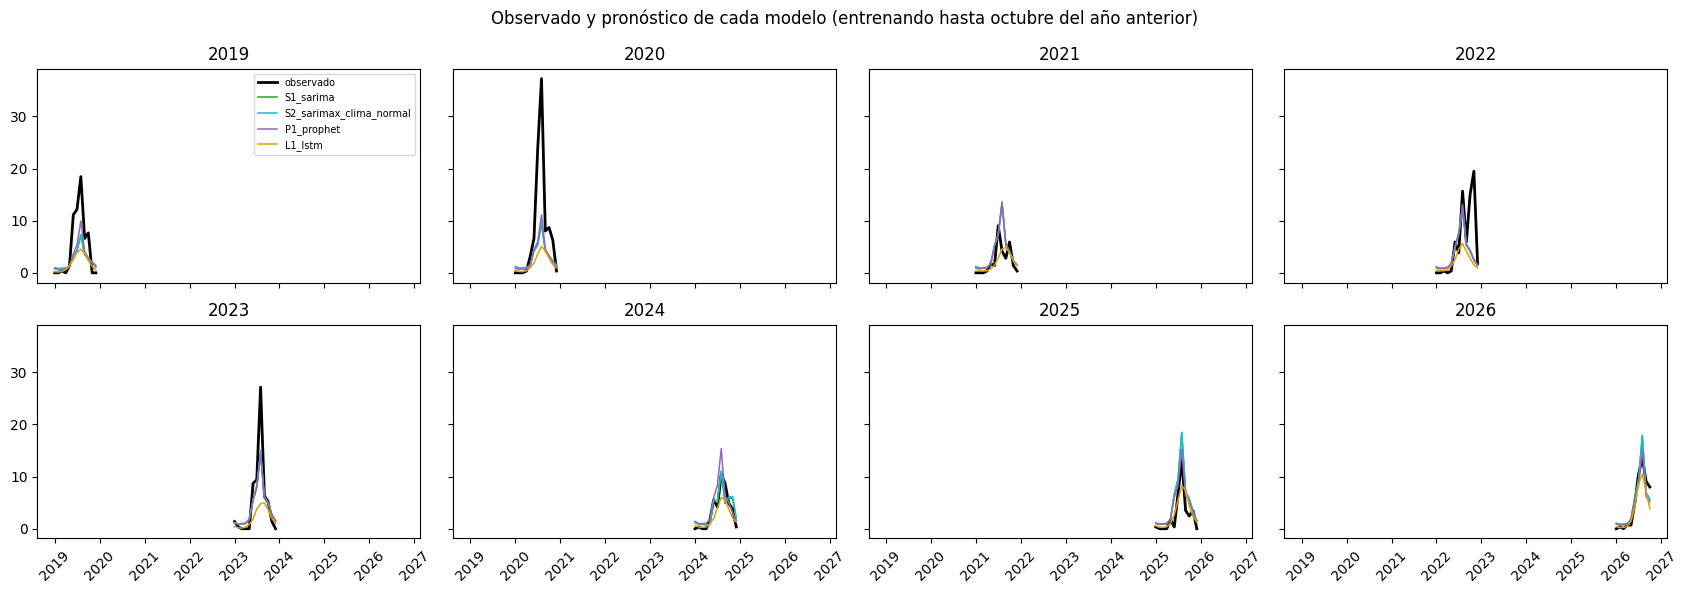

modelo,observado,L1_lstm,L2_lstm_clima,P1_prophet,P2_prophet_clima_normal,P2o_prophet_oraculo,S1_sarima,S2_sarimax_clima_normal,S2o_sarimax_oraculo,S3_sarimax_balance3m_clima_normal,S3o_sarimax_balance3m_oraculo
anio,,,,,,,,,,,
2019,58.0,21.0,24.0,33.0,35.0,27.0,29.0,30.0,26.0,28.0,34.0
2020,94.0,22.0,23.0,37.0,42.0,38.0,35.0,36.0,35.0,32.0,39.0
2021,27.0,24.0,31.0,45.0,50.0,37.0,44.0,46.0,42.0,36.0,44.0
2022,68.0,25.0,25.0,44.0,52.0,46.0,43.0,45.0,44.0,35.0,52.0
2023,60.0,24.0,49.0,48.0,55.0,55.0,48.0,51.0,50.0,37.0,54.0
2024,40.0,27.0,78.0,52.0,62.0,62.0,45.0,46.0,46.0,33.0,41.0
2025,32.0,34.0,50.0,51.0,59.0,52.0,57.0,58.0,57.0,38.0,35.0


In [17]:
fig, axs = plt.subplots(2, 4, figsize=(17, 6), sharex=True, sharey=True)
mostrar = ["S1_sarima", "S2_sarimax_clima_normal", "P1_prophet", "L1_lstm"]
paleta = {"S1_sarima": "#2ca02c", "S2_sarimax_clima_normal": "#17becf", "P1_prophet": "#9467bd", "L1_lstm": "#e0a000"}
for ax, (anio, g0) in zip(axs.ravel(), bt[bt.modelo == "S1_sarima"].groupby("anio")):
    ax.plot(g0.mes, g0.observado, "k-", lw=2, label="observado")
    for mod in mostrar:
        gm = bt[(bt.anio == anio) & (bt.modelo == mod)]
        ax.plot(gm.mes, gm.esperado, lw=1.1, color=paleta[mod], label=mod)
    ax.set_title(str(anio)); ax.tick_params(axis="x", labelrotation=45)
axs[0, 0].legend(fontsize=7)
plt.suptitle("Observado y pronóstico de cada modelo (entrenando hasta octubre del año anterior)"); plt.tight_layout(); plt.show()

an = bt[bt.anio <= 2025].groupby(["anio", "modelo"]).esperado.sum().unstack().round(0)
an.insert(0, "observado", bt[bt.anio <= 2025].drop_duplicates(["anio", "mes_num"]).groupby("anio").observado.sum().round(0))
an

### Cómo leer estos resultados

- Compare con la **binomial negativa del 09** (la mejor de esa ronda): un modelo más complejo solo vale la pena si la **supera con claridad** y la prueba de Diebold–Mariano dice que la diferencia **no es azar**.
- **SARIMAX con oráculo** es un **límite superior**: lo que aportaría el clima si lo conociéramos perfectamente. El que importa para decidir es el de **clima normal**.
- Si SARIMAX con clima normal **no mejora** a SARIMA, la señal climática no es aprovechable sin un buen pronóstico del clima.
- Los modelos flexibles (Prophet, LSTM) con pocos datos suelen **sobreajustar**: fíjese en el **sesgo** y en la **cobertura** de la banda, no solo en el error.

## 7. Pronóstico hasta diciembre de 2027

Se entrena con **toda la serie hasta octubre de 2026** y se pronostican noviembre-2026 a diciembre-2027. Para SARIMAX y Prophet con clima se muestran los tres escenarios
(**normal, seco y húmedo**): son escenarios condicionales, **no** un pronóstico del clima.

SARIMAX con balance hídrico de 3 meses (mismo mes): coeficiente = -0.754, p = 0.0000; AIC = 500.4 (SARIMA: 517.0)


Índice esperado de TODO 2027 (celdas-día MODIS-equivalentes):
modelo
L1_lstm                        40.3
L2_lstm_clima                  56.4
P1_prophet                     52.3
P2_prophet_clima_humedo        52.1
P2_prophet_clima_normal        60.5
P2_prophet_clima_seco          70.2
S1_sarima                      59.7
S2_sarimax_clima_humedo        58.7
S2_sarimax_clima_normal        60.8
S2_sarimax_clima_seco          63.0
S3_sarimax_balance3m_humedo    31.6
S3_sarimax_balance3m_normal    39.5
S3_sarimax_balance3m_seco      48.7

Referencia (09): binomial negativa = 46.3   |   media anual 2019-2025 = 54.2


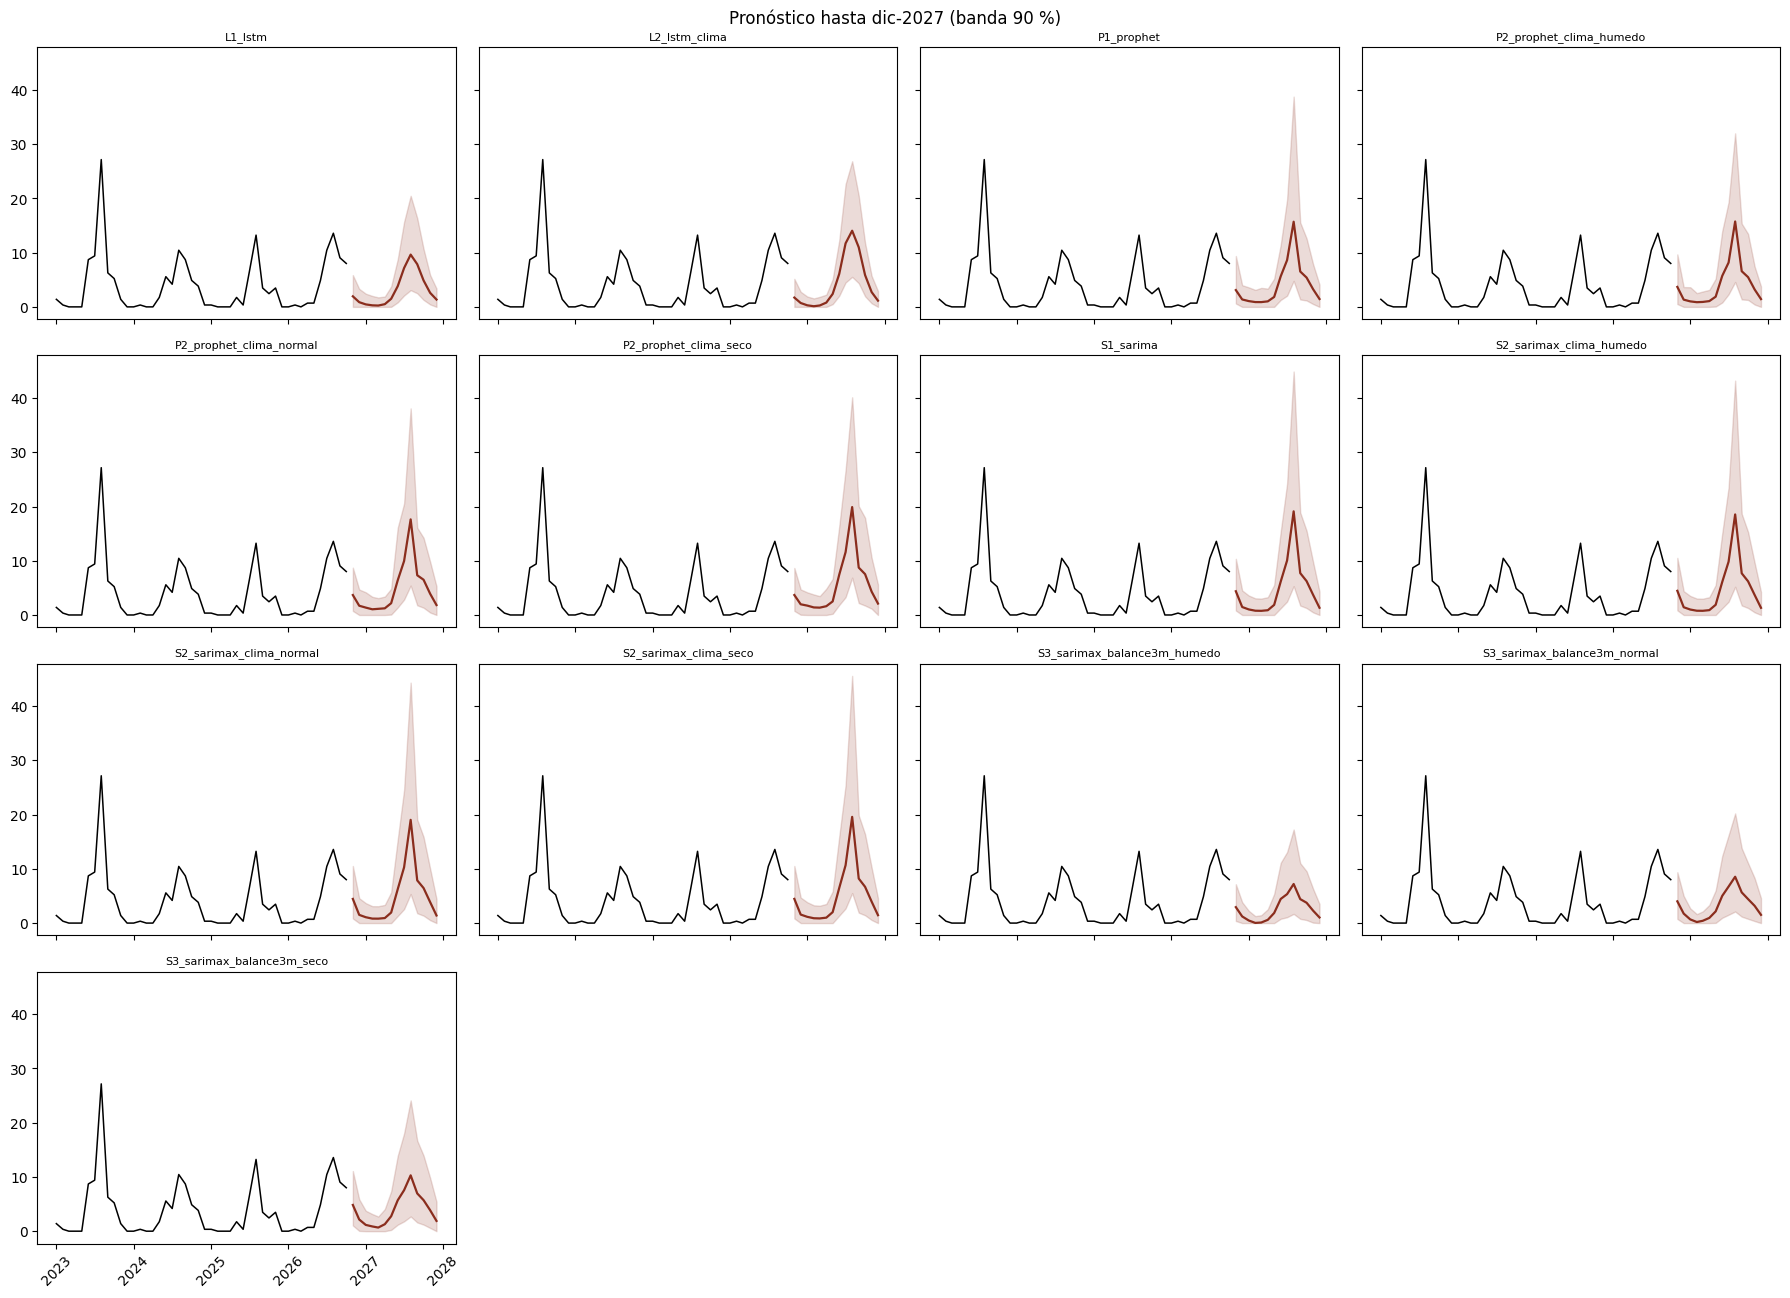

modelo,L1_lstm,L2_lstm_clima,P1_prophet,P2_prophet_clima_humedo,P2_prophet_clima_normal,P2_prophet_clima_seco,S1_sarima,S2_sarimax_clima_humedo,S2_sarimax_clima_normal,S2_sarimax_clima_seco,S3_sarimax_balance3m_humedo,S3_sarimax_balance3m_normal,S3_sarimax_balance3m_seco
mes_num,,,,,,,,,,,,,
1,0.5,0.3,1.1,1.0,1.4,1.7,1.0,1.0,1.1,1.2,0.5,0.7,1.2
2,0.3,0.1,0.9,0.9,1.0,1.4,0.8,0.8,0.8,0.9,0.0,0.2,0.9
3,0.2,0.3,0.9,0.9,1.1,1.4,0.8,0.8,0.8,0.9,0.1,0.4,0.7
4,0.5,0.8,1.0,1.1,1.2,1.6,0.9,0.9,0.9,1.0,0.6,1.0,1.3
5,1.5,2.4,1.8,1.9,2.2,2.5,1.9,1.9,1.9,2.0,1.9,2.2,2.8
6,3.8,6.1,5.6,5.7,6.4,7.4,6.2,6.1,6.3,6.5,4.5,5.0,5.7
7,7.2,11.7,8.6,8.2,10.0,11.6,10.1,9.8,10.3,10.7,5.3,6.7,7.6
8,9.6,14.0,15.7,15.7,17.6,19.9,19.1,18.5,19.0,19.6,7.2,8.5,10.3
9,7.9,11.0,6.5,6.6,7.3,8.7,7.7,7.7,7.9,8.2,4.4,5.7,7.0


In [18]:
ESC_FIN = ["climatologia", "seco", "humedo"]
finales = {}
yl = ylog.dropna()
yl.index.freq = "MS"
finales["S1_sarima"] = pronosticar_sm(res_sarima, yl, fut_final)
sxf, _, _ = modelos_sarimax(yl, sel_final, origen_final, fut_final, ESC_FIN)
for esc, nombre in zip(ESC_FIN, ["normal", "seco", "humedo"]):
    finales[f"S2_sarimax_clima_{nombre}"] = sxf[esc]
    finales[f"P2_prophet_clima_{nombre}"] = pron_prophet(yl, fut_final, Z=exog_extendida(origen_final, fut_final, esc))
sx3f, res_sx3, _ = modelos_sarimax(yl, sel_final, origen_final, fut_final, ESC_FIN, var="balance_3m", lag=0)
for esc, nombre in zip(ESC_FIN, ["normal", "seco", "humedo"]):
    finales[f"S3_sarimax_balance3m_{nombre}"] = sx3f[esc]
print(f"SARIMAX con balance hídrico de 3 meses (mismo mes): coeficiente = {res_sx3.params.get('x1', np.nan):.3f}, p = {res_sx3.pvalues.get('x1', np.nan):.4f}; AIC = {res_sx3.aic:.1f} (SARIMA: {res_sarima.aic:.1f})")
finales["P1_prophet"] = pron_prophet(yl, fut_final)
finales["L1_lstm"] = pron_lstm(yl, fut_final)
finales["L2_lstm_clima"] = pron_lstm(yl, fut_final, Z=exog_extendida(origen_final, fut_final, "climatologia"))

pron = pd.concat([df.assign(modelo=m).reset_index(names="mes") for m, df in finales.items()], ignore_index=True)
pron["area_id"] = AREA
pron["anio"], pron["mes_num"] = pron.mes.dt.year, pron.mes.dt.month
pron["horizonte_meses"] = (pron.anio - origen_final.year) * 12 + pron.mes_num - origen_final.month
pron["origen_hasta"] = origen_final.strftime("%Y-%m-%d")
pron["calidad_indice"] = "calibrado_localmente_en_tunari"
pron = pron.rename(columns={"esperado": "indice_esperado", "p05": "limite_inferior_p05", "p95": "limite_superior_p95"})
pron = pron[["area_id", "mes", "anio", "mes_num", "modelo", "indice_esperado", "limite_inferior_p05", "limite_superior_p95", "horizonte_meses", "origen_hasta", "calidad_indice"]]
pron[["indice_esperado", "limite_inferior_p05", "limite_superior_p95"]] = pron[["indice_esperado", "limite_inferior_p05", "limite_superior_p95"]].round(3)

tot = pron[pron.anio == 2027].groupby("modelo").indice_esperado.sum().round(1)
v09b = pd.read_csv(SALIDA / "pronostico_mensual_tunari.csv", parse_dates=["mes"])
bn27 = v09b[(v09b.modelo == "2_binomial_negativa") & (v09b.anio == 2027)].indice_esperado.sum()
print("Índice esperado de TODO 2027 (celdas-día MODIS-equivalentes):")
print(tot.to_string())
print(f"\nReferencia (09): binomial negativa = {bn27:.1f}   |   media anual 2019-2025 = {y.loc['2019':'2025'].groupby(y.loc['2019':'2025'].index.year).sum().mean():.1f}")

n_mod = pron.modelo.nunique()
filas_g = int(np.ceil(n_mod / 4))
fig, axs = plt.subplots(filas_g, 4, figsize=(18, 3.3 * filas_g), sharex=True, sharey=True)
hist = y.loc["2023-01-01":]
for ax, (mod, g_) in zip(axs.ravel(), pron.groupby("modelo")):
    ax.plot(hist.index, hist.values, "k-", lw=1.1)
    ax.plot(g_.mes, g_.indice_esperado, color="#8a2d1d", lw=1.6)
    ax.fill_between(g_.mes, g_.limite_inferior_p05, g_.limite_superior_p95, color="#8a2d1d", alpha=0.17)
    ax.set_title(mod, fontsize=8); ax.tick_params(axis="x", labelrotation=45)
for ax in axs.ravel()[n_mod:]:
    ax.axis("off")
plt.suptitle("Pronóstico hasta dic-2027 (banda 90 %)"); plt.tight_layout(); plt.show()
pron[pron.anio == 2027].pivot(index="mes_num", columns="modelo", values="indice_esperado").round(1)

In [19]:
# Guardar todo lo producido
pron.to_csv(SALIDA / "pronostico_modelos_avanzados_tunari.csv", index=False)
comparacion.to_csv(SALIDA / "comparacion_modelos_avanzados_tunari.csv")
bt.drop(columns=["anio", "mes_num"]).to_csv(SALIDA / "validacion_rodante_avanzados_tunari.csv", index=False)
adf_tabla.to_csv(SALIDA / "pruebas_estacionariedad_tunari.csv", index=False)
exo.assign(elegida=lambda d: (d.variable == EXOG_VAR) & (d.rezago_meses == EXOG_LAG)).to_csv(SALIDA / "analisis_exogena_tunari.csv", index=False)
pd.DataFrame(ordenes).to_csv(SALIDA / "ordenes_sarima_por_prueba_tunari.csv", index=False)
clima[CANDIDATAS].to_csv(SALIDA / "clima_mensual_tunari.csv")
print("Archivos en", SALIDA)
for f in sorted(SALIDA.glob("*avanzados*")) + [SALIDA / "pruebas_estacionariedad_tunari.csv", SALIDA / "analisis_exogena_tunari.csv", SALIDA / "clima_mensual_tunari.csv"]:
    print("  ", f.name)

Archivos en DATOS_PROCESADOS\pronostico
   comparacion_modelos_avanzados_tunari.csv
   pronostico_modelos_avanzados_tunari.csv
   validacion_rodante_avanzados_tunari.csv
   pruebas_estacionariedad_tunari.csv
   analisis_exogena_tunari.csv
   clima_mensual_tunari.csv


## Conclusiones de esta ejecución (datos hasta octubre de 2026)

> Los números de este cuadro son los de la ejecución que generó el notebook; si se rehace con otros datos, hay que releerlos de las tablas de arriba.

1. **Estacionariedad.** La serie en nivel no necesita diferencias (d = 0; D = 0 según OCSB y Canova–Hansen). En la serie completa, ADF dice «estacionaria» pero KPSS la rechaza; en la era VIIRS (2013+) las dos coinciden. Es coherente con un **cambio de nivel en 2012** (paso de MODIS a VIIRS).
2. **SARIMA.** El orden elegido fue casi siempre `(1,0,0)(1,0,1)12`. El coeficiente AR estacional es ≈ 1 (compensado por el MA estacional): el ciclo anual es muy persistente. Los residuos no tienen autocorrelación (Ljung–Box p > 0,8) pero no son normales (hay muchos ceros y picos).
3. **Variable exógena (clima).** Con **1 mes o más de anticipación no hay señal**: ninguna candidata supera la prueba de Granger (p mínimo 0,149) y la elegida (`tmax_media`, rezago 1) no aporta (coeficiente p = 0,37; razón de verosimilitud p = 0,44). La asociación fuerte es con el clima **del mismo mes**: el balance hídrico de 3 meses entra en SARIMAX con coeficiente −0,75 (p < 0,001) y baja el AIC de 517 a 500. Sirve para **explicar** un mes, no para predecirlo.
4. **Validación (8 años de prueba).** Ningún modelo **realista** supera a la binomial negativa del notebook 09 (41,2 % de error anual): Prophet 44,0 %, SARIMAX con clima normal 44,7 %, SARIMA 45,4 %. El **LSTM es el peor** (54,3 % y 57,9 %; con clima es significativamente peor, Diebold–Mariano p = 0,042).
5. **Solo con el clima real del mes conocido de antemano** (el «oráculo») baja a **32,3 %** de error anual. Pero su error mensual (56,6 %) es peor que el de la binomial negativa (53,0 %) y la diferencia **no es significativa** (p = 0,39). El clima ayudaría solo con un **buen pronóstico climático estacional**, que no tenemos.
6. **2027.** Los modelos dan entre **32 y 70 celdas-día** según el modelo y el escenario (SARIMA 59,7; Prophet 52,3; SARIMAX con balance hídrico: húmedo 31,6 · normal 39,5 · seco 48,7; LSTM 40,3). La diferencia entre modelos es tan grande como la que hay entre años: **esa es la incertidumbre real**.
7. **Recomendación.** Mantener la binomial negativa del 09 (46,3) como pronóstico principal y usar SARIMAX con balance hídrico para **escenarios condicionales** («si el año es seco, esperar más»), no como pronóstico.

## 8. Límites que hay que decir en voz alta

1. **Con pocos datos, lo complejo no garantiza mejor.** 303 meses y 13 temporadas con VIIRS son poco para Prophet y, sobre todo, para un LSTM. Lo que importa es la comparación honesta de arriba.
2. **La variable climática no se conoce a futuro.** El pronóstico con clima es **condicional a un escenario**. El «oráculo» es solo un límite superior de la validación.
3. **Un solo punto de ERA5** (~4.200 m) para un parque con gran desnivel: es un indicador regional.
4. **La elección de la variable exógena** se hizo con datos hasta 2018, pero la comparación final sigue siendo sobre **8 años de prueba**; con tan pocos hay que tomar las diferencias pequeñas con cautela.
5. **La serie de clima de 2026** llega hasta el 7 de noviembre (con los últimos días provisionales) y se **volvió a bajar completa (2000–2026)** para que sea coherente (la temperatura y la evapotranspiración cambian ligeramente con el ajuste de altitud de la fuente; la lluvia no).
6. **Fuga leve del factor de armonización** (2013–2025), igual que en el notebook 09.
7. **Una detección no es un incendio:** se pronostica el nivel de actividad de calor, no incendios concretos.